In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Dataset and Split Tools
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
# Classification Models, Scaling, and Evaluation Metrics
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [11]:
#1.DATA PREPARATION & BINARY CONVERSION
#Load the baseline Iris classification dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
#This leaves only Class 0 (Setosa) and Class 1 (Versicolor)
binary_df = df[df['target'] != 2]
# Split into Independent (X) and Dependent (y) variables
X = binary_df.iloc[:, :-1]
y = binary_df.iloc[:, -1]
# 80-20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
#2.FEATURE SCALING
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
#3.MODEL TRAINING & HYPERPARAMETER TUNING
classifier = LogisticRegression()

In [12]:
classifier = LogisticRegression(max_iter=10000)
parameters = {
    'penalty': ['l1', 'l2'],
    'C': [0.001, 0.01, 0.1, 1, 10, 20, 50, 100],
    'solver': ['liblinear', 'saga']
}
cv_classifier = GridSearchCV(classifier, param_grid=parameters, scoring='accuracy', cv=5)
cv_classifier.fit(X_train_scaled, y_train)
print("--- TUNING COMPLETION ---")
print(f"Optimal Hyperparameters selected: {cv_classifier.best_params_}")
print(f"Best Validation Accuracy achieved: {cv_classifier.best_score_:.4f}\n")

--- TUNING COMPLETION ---
Optimal Hyperparameters selected: {'C': 0.001, 'penalty': 'l2', 'solver': 'liblinear'}
Best Validation Accuracy achieved: 1.0000



In [13]:
#4.PREDICTIONS & PROBABILITY MASKS
#Class Predictions (0 or 1 based on default 0.5 Sigmoid threshold)
y_pred = cv_classifier.predict(X_test_scaled)
# Probability Outputs (Returns raw probability scores for both classes)
y_prob = cv_classifier.predict_proba(X_test_scaled)
print("RAW CLASS PROBABILITIES(First 3 samples)")
print(y_prob[:3], "\n")

RAW CLASS PROBABILITIES(First 3 samples)
[[0.46163786 0.53836214]
 [0.47351388 0.52648612]
 [0.46805434 0.53194566]] 



In [14]:
#5.CORE CLASSIFICATION EVALUATION METRICS
print("PERFORMANCE EVALUATION METRICS")
print(f"Overall Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("CONFUSION MATRIX")
conf_matrix = confusion_matrix(y_test, y_pred)
print(conf_matrix, "\n")
print("CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

PERFORMANCE EVALUATION METRICS
Overall Accuracy Score: 1.0000

CONFUSION MATRIX
[[12  0]
 [ 0  8]] 

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



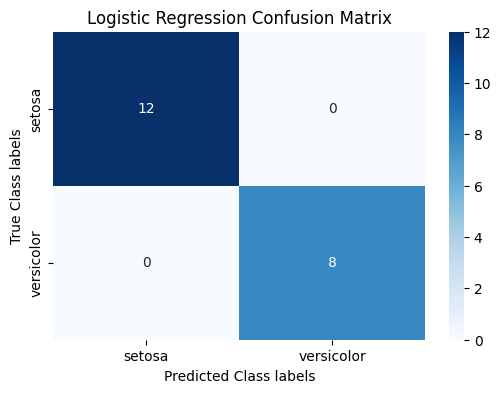

In [15]:
#6.CONFUSION MATRIX VISUALIZATION
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names[:2], yticklabels=iris.target_names[:2])
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class labels")
plt.ylabel("True Class labels")
plt.show()